# Métodos Numéricos I — Notebook da Aula 8
## Métodos Iterativos Avançados: Newton e Secante

**Programa:** PPGMC / UESC  
**Referências-base:** Burden & Faires cap. 2; Epperson cap. 3.

Este notebook acompanha a **Aula 8 — Métodos Iterativos Avançados**.

## Objetivos

- gerar figuras para os slides da aula;
- implementar o **método de Newton**;
- implementar o **método da secante**;
- comparar Newton, secante e bisseção;
- visualizar taxas de convergência;
- discutir critérios de parada;
- mostrar exemplos de convergência e falha.

O exemplo principal será:

\[
f(x)=x^3-x-2.
\]

## 1. Bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 2. Função principal da aula

Usaremos:

$$
f(x)=x^3-x-2
$$

com derivada:

$$
f'(x)=3x^2-1
$$

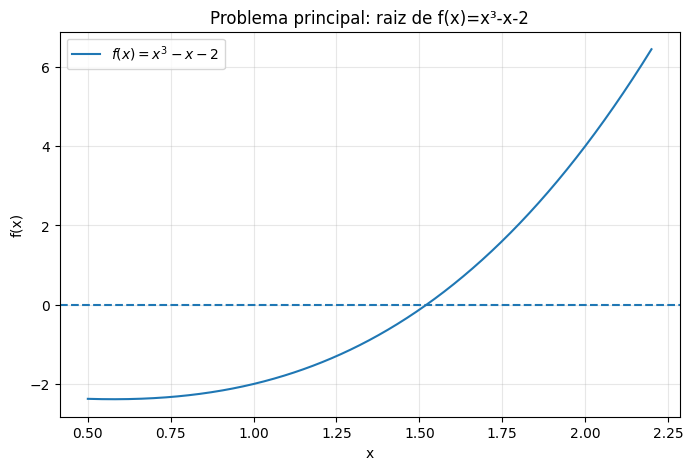

In [2]:
def f(x):
    return x**3 - x - 2

def df(x):
    return 3*x**2 - 1

x = np.linspace(0.5, 2.2, 600)

plt.figure(figsize=(8,5))
plt.plot(x, f(x), label=r"$f(x)=x^3-x-2$")
plt.axhline(0, linestyle="--")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Problema principal: raiz de f(x)=x³-x-2")
plt.legend()
plt.show()

## 3. Método de Newton

A fórmula de Newton é:

$$
x_{n+1}=x_n-\frac{f(x_n)}{f'(x_n)}.
$$

Ela vem da aproximação linear de Taylor:

$$
f(x)\approx f(x_n)+f'(x_n)(x-x_n).
$$

In [3]:
from pyNuMeth import newton

raiz_newton, hist_newton = newton(f, df, x0=1.5, tol=1e-12)

print("Raiz aproximada:", raiz_newton)
print("f(raiz):", f(raiz_newton))
print("Iterações:", len(hist_newton))

for item in hist_newton:
    print(item)

Raiz aproximada: 1.5213797068045751
f(raiz): 4.529709940470639e-14
Iterações: 3
{'iter': 1, 'x': 1.5, 'f(x)': -0.125, "f'(x)": 5.75, 'x_next': 1.5217391304347827, 'erro': 0.021739130434782705}
{'iter': 2, 'x': 1.5217391304347827, 'f(x)': 0.0021369277554046384, "f'(x)": 5.947069943289225, 'x_next': 1.5213798059647863, 'erro': 0.00035932446999642487}
{'iter': 3, 'x': 1.5213798059647863, 'f(x)': 5.893874259754739e-07, "f'(x)": 5.943789541992352, 'x_next': 1.5213797068045751, 'erro': 9.916021115330409e-08}


## 4. Figura: interpretação geométrica de Newton

Esta figura mostra:
- o ponto inicial \(x_0\);
- a tangente em \(x_0\);
- a interseção da tangente com o eixo \(x\), que gera \(x_1\).

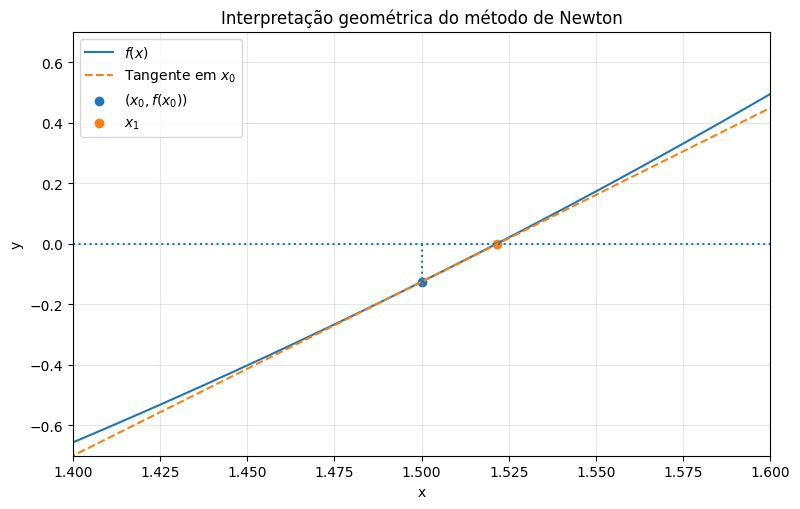

In [4]:
x0 = 1.5
x1 = x0 - f(x0)/df(x0)

x_curve = np.linspace(0.8, 2.1, 600)
y_curve = f(x_curve)
tangent = f(x0) + df(x0)*(x_curve - x0)

plt.figure(figsize=(9,5.5))
plt.plot(x_curve, y_curve, label=r"$f(x)$")
plt.plot(x_curve, tangent, "--", label="Tangente em $x_0$")
plt.axhline(0, linestyle=":")
plt.scatter([x0], [f(x0)], label=r"$(x_0,f(x_0))$")
plt.scatter([x1], [0], label=r"$x_1$")
plt.vlines(x0, 0, f(x0), linestyles=":")
plt.grid(True, alpha=0.3)
# definir o intervalo do gráfico para melhor visualização
plt.xlim(1.4, 1.6)
plt.ylim(-0.7, 0.7)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Interpretação geométrica do método de Newton")
plt.legend()
plt.show()

## 5. Newton: sequência de aproximações

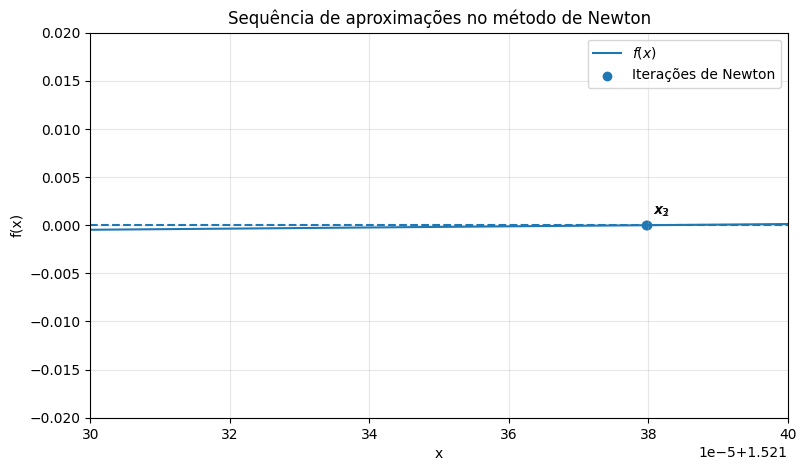

In [5]:
xs_newton = [item["x"] for item in hist_newton] + [raiz_newton]
ys_newton = [f(xi) for xi in xs_newton]

x_curve = np.linspace(1.0, 1.8, 600)

plt.figure(figsize=(9,5))
plt.plot(x_curve, f(x_curve), label=r"$f(x)$")
plt.axhline(0, linestyle="--")
plt.scatter(xs_newton[2:4], ys_newton[2:4], label="Iterações de Newton")
for i, xi in enumerate(xs_newton): 
    if i > 1 and i < 4:
        plt.annotate(f"$x_{i}$", (xi, f(xi)), textcoords="offset points", xytext=(5,8))
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Sequência de aproximações no método de Newton")
plt.xlim(1.5213, 1.5214)
plt.ylim(-0.02, 0.02)
plt.legend()
plt.show()

## 6. Método da secante

A secante evita o cálculo explícito da derivada.

Aproxima-se:

$$
f'(x_n)\approx \frac{f(x_n)-f(x_{n-1})}{x_n-x_{n-1}}.
$$

Logo:

$$
x_{n+1}=x_n-
f(x_n)\frac{x_n-x_{n-1}}{f(x_n)-f(x_{n-1})}.
$$

In [6]:
from pyNuMeth import secante

raiz_secante, hist_secante = secante(f, x0=1.0, x1=2.0, tol=1e-12)

print("Raiz aproximada:", raiz_secante)
print("f(raiz):", f(raiz_secante))
print("Iterações:", len(hist_secante))

for item in hist_secante:
    print(item)

Raiz aproximada: 1.5213797068045645
f(raiz): -1.84297022087776e-14
Iterações: 7
{'iter': 1, 'x_prev': 1.0, 'x_curr': 2.0, 'f(x_curr)': 4.0, 'x_next': 1.3333333333333335, 'erro': 0.6666666666666665}
{'iter': 2, 'x_prev': 2.0, 'x_curr': 1.3333333333333335, 'f(x_curr)': -0.9629629629629624, 'x_next': 1.462686567164179, 'erro': 0.12935323383084563}
{'iter': 3, 'x_prev': 1.3333333333333335, 'x_curr': 1.462686567164179, 'f(x_curr)': -0.3333388747951045, 'x_next': 1.5311694321412044, 'erro': 0.06848286497702527}
{'iter': 4, 'x_prev': 1.462686567164179, 'x_curr': 1.5311694321412044, 'f(x_curr)': 0.05862641770944954, 'x_next': 1.5209264205152802, 'erro': 0.010243011625924225}
{'iter': 5, 'x_prev': 1.5311694321412044, 'x_curr': 1.5209264205152802, 'f(x_curr)': -0.0026933002019968733, 'x_next': 1.5213763166697438, 'erro': 0.00044989615446366926}
{'iter': 6, 'x_prev': 1.5209264205152802, 'x_curr': 1.5213763166697438, 'f(x_curr)': -2.0150192387102805e-05, 'x_next': 1.5213797079848717, 'erro': 3.391

## 7. Figura: interpretação geométrica da secante

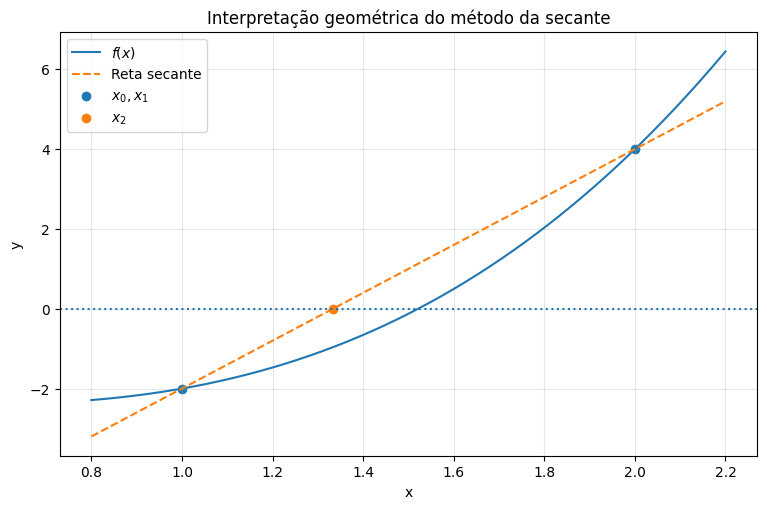

In [7]:
x0, x1 = 1.0, 2.0
x2 = x1 - f(x1)*(x1-x0)/(f(x1)-f(x0))

x_curve = np.linspace(0.8, 2.2, 600)
m = (f(x1)-f(x0))/(x1-x0)
sec_line = f(x1) + m*(x_curve-x1)

plt.figure(figsize=(9,5.5))
plt.plot(x_curve, f(x_curve), label=r"$f(x)$")
plt.plot(x_curve, sec_line, "--", label="Reta secante")
plt.axhline(0, linestyle=":")
plt.scatter([x0, x1], [f(x0), f(x1)], label=r"$x_0,x_1$")
plt.scatter([x2], [0], label=r"$x_2$")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Interpretação geométrica do método da secante")
plt.legend()
plt.show()

## 8. Bisseção para comparação

In [8]:
from pyNuMeth import bissecao

raiz_bis, hist_bis = bissecao(f, 1, 2, tol=1e-12)

print("Raiz aproximada:", raiz_bis)
print("Iterações:", len(hist_bis))
print("f(raiz):", f(raiz_bis))

Raiz aproximada: 1.5213797068045096
Iterações: 39
f(raiz): -3.446132268436486e-13


## 9. Comparação de convergência

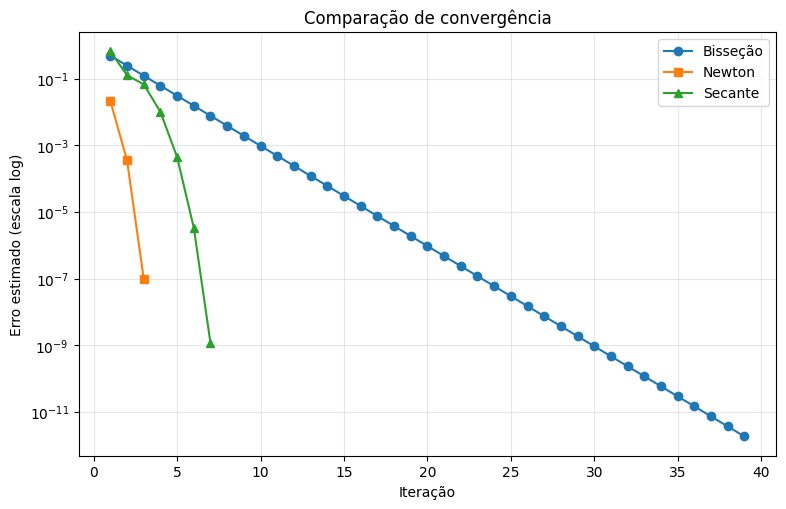

In [10]:
erros_bis = np.array([item["erro_intervalo"] for item in hist_bis])
erros_newton = np.array([item["erro"] for item in hist_newton])
erros_secante = np.array([item["erro"] for item in hist_secante])

plt.figure(figsize=(9,5.5))
plt.plot(range(1, len(erros_bis)+1), erros_bis, marker="o", label="Bisseção")
plt.plot(range(1, len(erros_newton)+1), erros_newton, marker="s", label="Newton")
plt.plot(range(1, len(erros_secante)+1), erros_secante, marker="^", label="Secante")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.xlabel("Iteração")
plt.ylabel("Erro estimado (escala log)")
plt.title("Comparação de convergência")
plt.legend()
plt.show()

## 10. Tabela comparativa

In [11]:
print("Método      | Raiz aproximada       | Iterações | |f(raiz)|")
print("-"*65)
print(f"Bisseção    | {raiz_bis:.15f} | {len(hist_bis):9d} | {abs(f(raiz_bis)):.3e}")
print(f"Newton      | {raiz_newton:.15f} | {len(hist_newton):9d} | {abs(f(raiz_newton)):.3e}")
print(f"Secante     | {raiz_secante:.15f} | {len(hist_secante):9d} | {abs(f(raiz_secante)):.3e}")

Método      | Raiz aproximada       | Iterações | |f(raiz)|
-----------------------------------------------------------------
Bisseção    | 1.521379706804510 |        39 | 3.446e-13
Newton      | 1.521379706804575 |         3 | 4.530e-14
Secante     | 1.521379706804564 |         7 | 1.843e-14


## 11. Estimativa empírica da ordem de convergência

Para uma sequência de erros \(e_n\), a ordem \(p\) pode ser estimada por:

$$
p \approx
\frac{\log(e_{n+1}/e_n)}
{\log(e_n/e_{n-1})}.
$$

In [ ]:
def estimar_ordem(erros):
    erros = np.array(erros, dtype=float)
    ps = []
    for i in range(1, len(erros)-1):
        if erros[i-1] > 0 and erros[i] > 0 and erros[i+1] > 0:
            den = np.log(erros[i]/erros[i-1])
            if abs(den) > 1e-14:
                p = np.log(erros[i+1]/erros[i]) / den
                ps.append(p)
    return ps

p_newton = estimar_ordem(erros_newton)
p_secante = estimar_ordem(erros_secante)

print("Estimativas de ordem - Newton:")
print(p_newton)

print("\nEstimativas de ordem - Secante:")
print(p_secante)

Estimativas de ordem - Newton:
[np.float64(1.9975521900530264)]

Estimativas de ordem - Secante:
[np.float64(0.3878432411063269), np.float64(2.987574540600534), np.float64(1.644923208323511), np.float64(1.5639284412795436), np.float64(1.6291992242868076)]


## 12. Critérios de parada

Critérios comuns:

$$
|x_{n+1}-x_n|<\varepsilon
$$

$$
|f(x_n)|<\varepsilon
$$

$$
\frac{|x_{n+1}-x_n|}{|x_{n+1}|}<\varepsilon
$$

In [13]:
def newton_com_criterios(f, df, x0, tol_x=1e-8, tol_f=1e-8, max_iter=50):
    xk = x0
    hist = []

    for k in range(1, max_iter+1):
        fx = f(xk)
        dfx = df(xk)
        x_next = xk - fx/dfx

        inc_abs = abs(x_next-xk)
        inc_rel = inc_abs / max(abs(x_next), 1e-14)
        residuo = abs(f(x_next))

        hist.append((k, x_next, inc_abs, inc_rel, residuo))

        if inc_abs < tol_x and residuo < tol_f:
            return x_next, hist, "Convergiu por incremento e resíduo"

        xk = x_next

    return xk, hist, "Máximo de iterações atingido"

raiz_crit, hist_crit, status = newton_com_criterios(f, df, 1.5)
print(status)
for linha in hist_crit:
    print(linha)

Convergiu por incremento e resíduo
(1, 1.5217391304347827, 0.021739130434782705, 0.014285714285714348, 0.0021369277554046384)
(2, 1.5213798059647863, 0.00035932446999642487, 0.00023618327822391363, 5.893874259754739e-07)
(3, 1.5213797068045751, 9.916021115330409e-08, 6.517781899534792e-08, 4.529709940470639e-14)
(4, 1.5213797068045676, 7.549516567451064e-15, 4.962282942045878e-15, 0.0)


## 13. Exemplo de falha do Método de Newton

Newton pode falhar quando:
- a derivada é próxima de zero;
- o chute inicial é ruim;
- a função possui geometria desfavorável.

Exemplo:

$$
f(x)=x^3-2x+2
$$

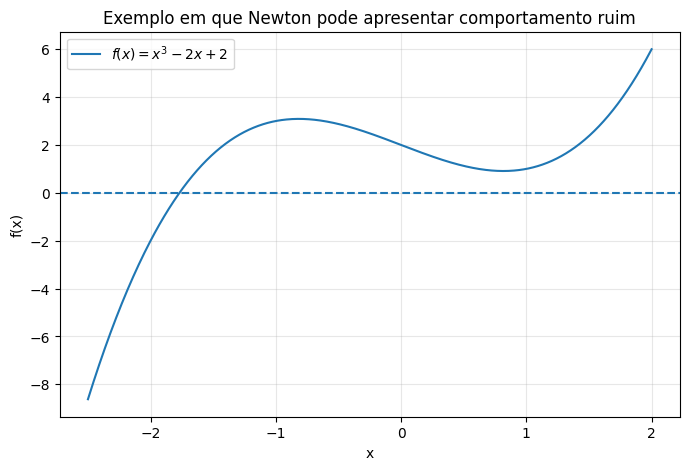

In [14]:
def f_fail(x):
    return x**3 - 2*x + 2

def df_fail(x):
    return 3*x**2 - 2

x_curve = np.linspace(-2.5, 2.0, 600)

plt.figure(figsize=(8,5))
plt.plot(x_curve, f_fail(x_curve), label=r"$f(x)=x^3-2x+2$")
plt.axhline(0, linestyle="--")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Exemplo em que Newton pode apresentar comportamento ruim")
plt.legend()
plt.show()

[1. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1.]


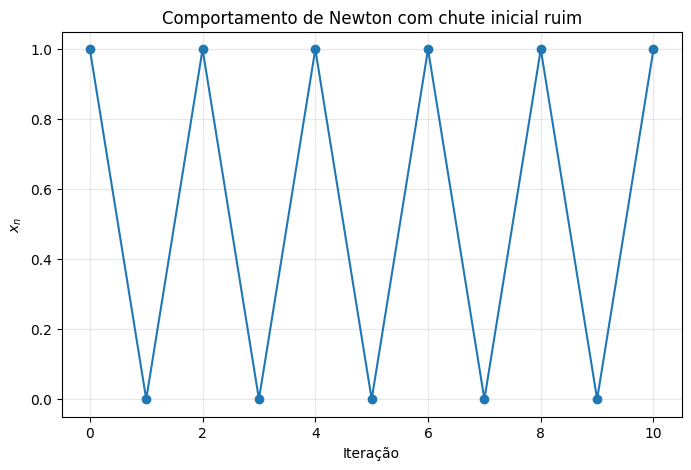

In [23]:
def newton_sem_interromper(f, df, x0, n_iter=10):
    xs = [x0]
    xk = x0
    for _ in range(n_iter):
        xk = xk - f(xk)/df(xk)
        xs.append(xk)
    return np.array(xs)

seq_fail = newton_sem_interromper(f_fail, df_fail, x0=1, n_iter=10)

print(seq_fail)

plt.figure(figsize=(8,5))
plt.plot(seq_fail, marker="o")
plt.grid(True, alpha=0.3)
plt.xlabel("Iteração")
plt.ylabel(r"$x_n$")
plt.title("Comportamento de Newton com chute inicial ruim")
plt.show()

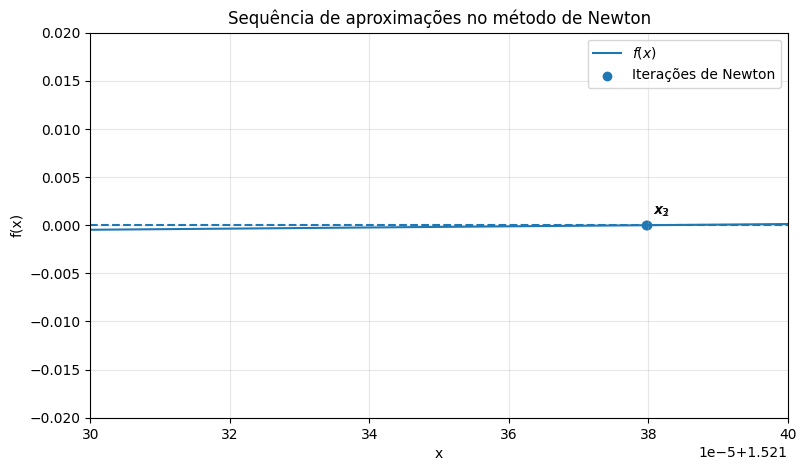

In [16]:
xs_newton = [item["x"] for item in hist_newton] + [raiz_newton]
ys_newton = [f(xi) for xi in xs_newton]

x_curve = np.linspace(1.0, 1.8, 600)

plt.figure(figsize=(9,5))
plt.plot(x_curve, f(x_curve), label=r"$f(x)$")
plt.axhline(0, linestyle="--")
plt.scatter(xs_newton[2:4], ys_newton[2:4], label="Iterações de Newton")
for i, xi in enumerate(xs_newton): 
    if i > 1 and i < 4:
        plt.annotate(f"$x_{i}$", (xi, f(xi)), textcoords="offset points", xytext=(5,8))
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Sequência de aproximações no método de Newton")
plt.xlim(1.5213, 1.5214)
plt.ylim(-0.02, 0.02)
plt.legend()
plt.show()

## 14. Exemplo aplicado: circuito com diodo

Para um circuito com diodo:

$$
f(I)=I-I_s\left(e^{\frac{V-RI}{nV_T}}-1\right)=0.
$$

Agora podemos resolver com Newton e comparar com bisseção.

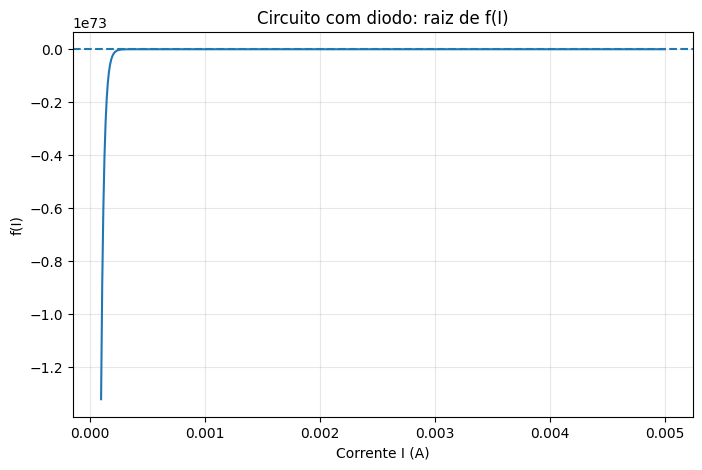

In [17]:
Is = 1e-12
V = 5.0
R = 1000.0
VT = 0.025
n = 1.0

def f_diodo(I):
    return I - Is*(np.exp((V - R*I)/(n*VT)) - 1)

def df_diodo(I):
    return 1 + Is*np.exp((V - R*I)/(n*VT))*(R/(n*VT))

I_vals = np.linspace(0.0001, 0.005, 1000)

plt.figure(figsize=(8,5))
plt.plot(I_vals, f_diodo(I_vals))
plt.axhline(0, linestyle="--")
plt.grid(True, alpha=0.3)
plt.xlabel("Corrente I (A)")
plt.ylabel("f(I)")
plt.title("Circuito com diodo: raiz de f(I)")
plt.show()

In [18]:
raiz_diodo_newton, hist_diodo_newton = newton(f_diodo, df_diodo, x0=0.004, tol=1e-12, max_iter=100)
raiz_diodo_bis, hist_diodo_bis = bissecao(f_diodo, 0.0001, 0.005, tol=1e-12, max_iter=200)

print("Newton:")
print("Corrente:", raiz_diodo_newton, "A")
print("Iterações:", len(hist_diodo_newton))
print("f(I):", f_diodo(raiz_diodo_newton))

print("\nBisseção:")
print("Corrente:", raiz_diodo_bis, "A")
print("Iterações:", len(hist_diodo_bis))
print("f(I):", f_diodo(raiz_diodo_bis))

Newton:
Corrente: 0.004444625961140645 A
Iterações: 22
f(I): -1.06433958868557e-14

Bisseção:
Corrente: 0.004444625961233395 A
Iterações: 33
f(I): 1.657147596229036e-11


## 15. Síntese da aula

Nesta aula vimos que:

- Newton é muito rápido quando converge;
- a secante dispensa derivadas e mantém convergência superlinear;
- a bisseção é mais robusta, mas mais lenta;
- critérios de parada precisam combinar incremento, resíduo e limite de iterações;
- métodos rápidos exigem análise cuidadosa de estabilidade e inicialização.